In [1]:
from dandi.dandiapi import DandiAPIClient
import fsspec
import pynwb
import h5py
from fsspec.implementations.cached import CachingFileSystem
import os
from matplotlib import pyplot as plt
import numpy as np

In [3]:
dandiset_id = '000727'
subject_ids = ['087', '089', '094', '097', '098', '099', '100', '101', '105']
filepaths = [f'sub-fly-{id}/sub-fly-{id}_ses-20200228161226_behavior+image+ophys.nwb' for id in subject_ids]

nwbfile = None
for filepath in filepaths[:1]:

	with DandiAPIClient() as client:
		asset = client.get_dandiset(dandiset_id, 'draft').get_asset_by_path(filepath)
		s3_url = asset.get_content_url(follow_redirects=1, strip_query=True)
	fs = fsspec.filesystem("http")
	fs = CachingFileSystem(
		fs=fs,
		cache_storage="nwb-cache",
	)
	f = fs.open(s3_url, "rb")
	file = h5py.File(f)
	io = pynwb.NWBHDF5IO(file=file)
	nwbfile = io.read()

/home/julian-zim/.venv/hgm/lib/python3.12/site-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'core' version 2.6.0-alpha because version 2.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."


In [4]:
os.makedirs('ophys', exist_ok=True)
container = nwbfile.processing['ophys'].data_interfaces
for key in container.keys():
	data = container[key].data
	with h5py.File(f'ophys/{key}.h5', 'a') as f:
		dset = f.create_dataset(key, data=data)
		#os.system('pause')
	print(f'processed {key}')

MemoryError: Unable to allocate 52.6 GiB for an array with shape (3384, 314, 146, 91) and data type float32

In [ ]:
os.makedirs('behavior', exist_ok=True)
container = nwbfile.processing['behavior'].data_interfaces['FicTrac'].spatial_series
for key in container.keys():
	data = container[key].data
	with h5py.File(f'behavior/{key}.h5', 'w') as f:
		dset = f.create_dataset(key, data=data)
	print(f'processed {key}')

In [2]:
def plotgrid(datas, labels):
	ncols = 4
	nplots = len(datas)

	nrows = (nplots + ncols - 1) // ncols
	fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, nrows * 4))
	axes = axes.flatten()

	for i in range(nplots):
		ax = axes[i]

		x = datas[i][:1000]
		l = labels[i]

		ax.plot(x)
		ax.set_title(f"Plot {i+1}")
		ax.set_xlabel("Time (s)")
		ax.set_ylabel(l)
		xtick_positions = np.arange(0, 90000, 100)
		xtick_labels = [f'{x / 50:.0f}' for x in xtick_positions]
		ax.set_xticks(xtick_positions[:10], xtick_labels[:10])

		if i >= nplots:
			ax.set_visible(False)

	plt.tight_layout()
	plt.show()

Keys: ['SpatialSeriesAnimalHeading']
Keys: ['SpatialSeriesIntegratedMotion']
Keys: ['SpatialSeriesMovementDirection']
Keys: ['SpatialSeriesMovementSpeed']
Keys: ['SpatialSeriesPosition']
Keys: ['SpatialSeriesRotationCameraFrame']
Keys: ['SpatialSeriesRotationDeltaCameraFrame']
Keys: ['SpatialSeriesRotationDeltaError']
Keys: ['SpatialSeriesRotationDeltaLabFrame']
Keys: ['SpatialSeriesRotationLabFrame']


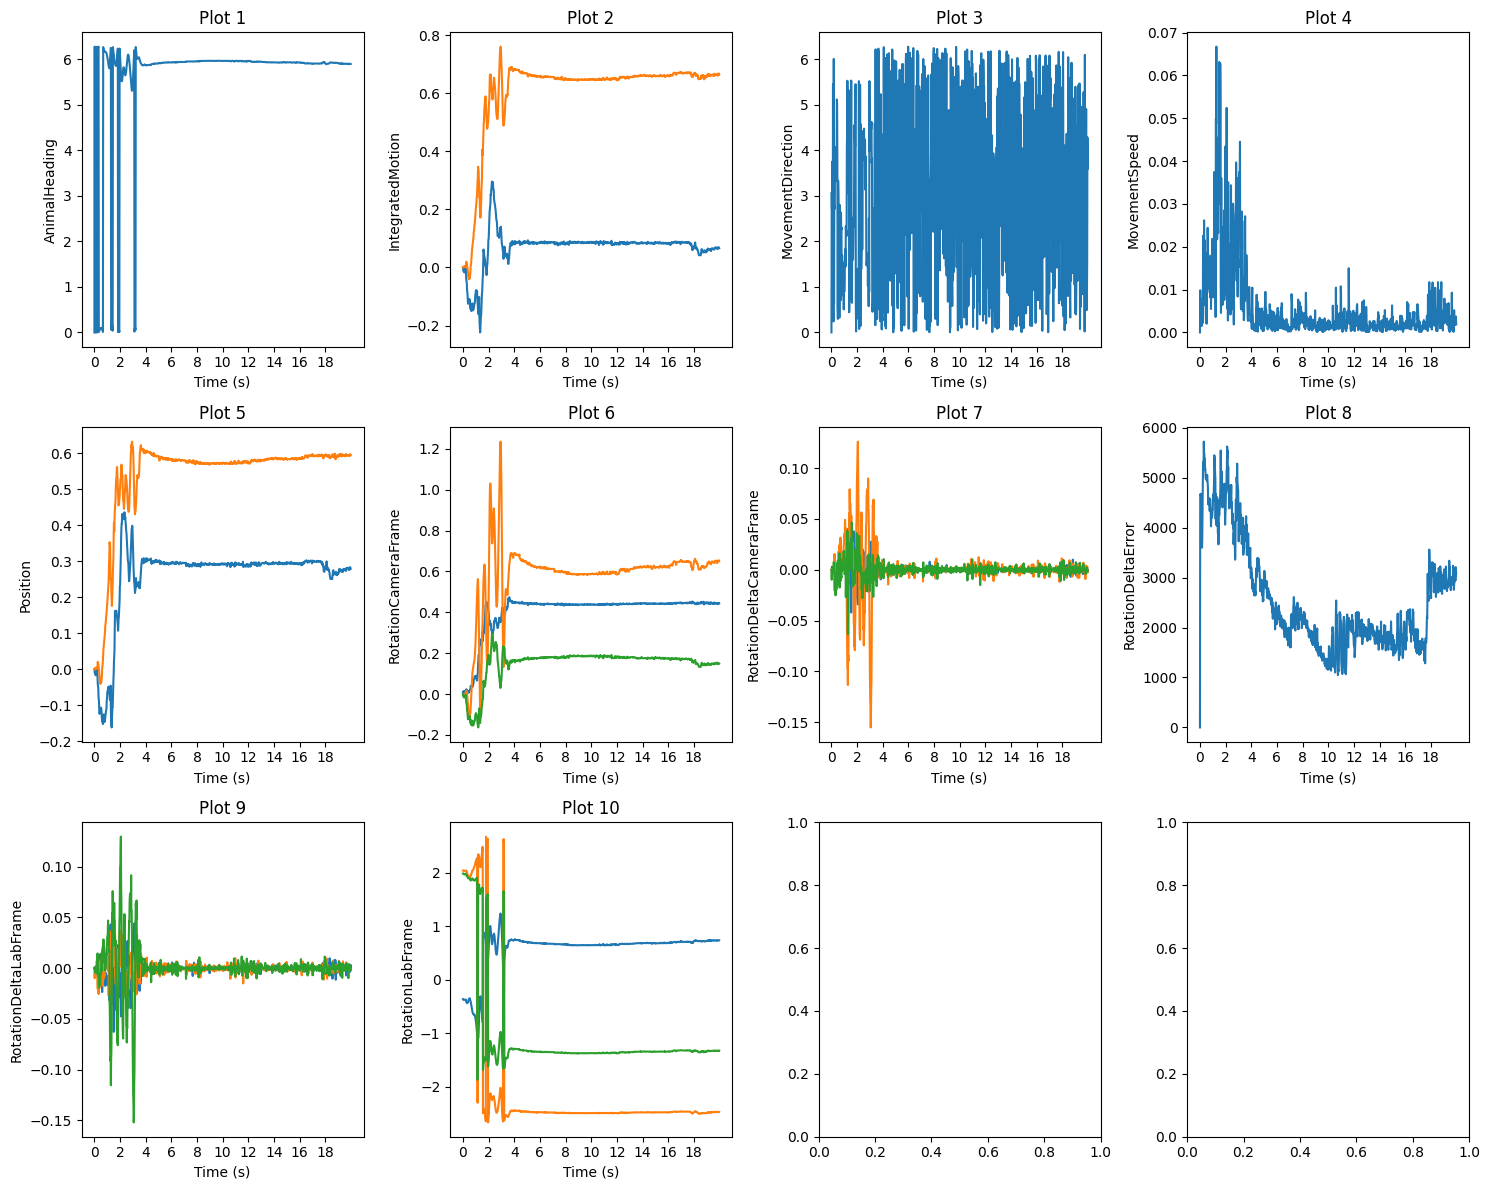

In [17]:
filenames = ['AnimalHeading',
		 'IntegratedMotion',
		 'MovementDirection',
		 'MovementSpeed',
		 'Position',
		 'RotationCameraFrame',
		 'RotationDeltaCameraFrame',
		 'RotationDeltaError',
		 'RotationDeltaLabFrame',
		 'RotationLabFrame']


datas = list()
descrs = list()
for filename in filenames:
	filepath = f'./sub-fly-087/behavior/SpatialSeries{filename}.h5'
	file = h5py.File(f'{filepath}', 'r')
	print("Keys: %s" % list(file.keys()))
	datas.append(file[f'SpatialSeries{filename}'][:])
	#descrs.append(file.description)

plotgrid(datas, filenames)

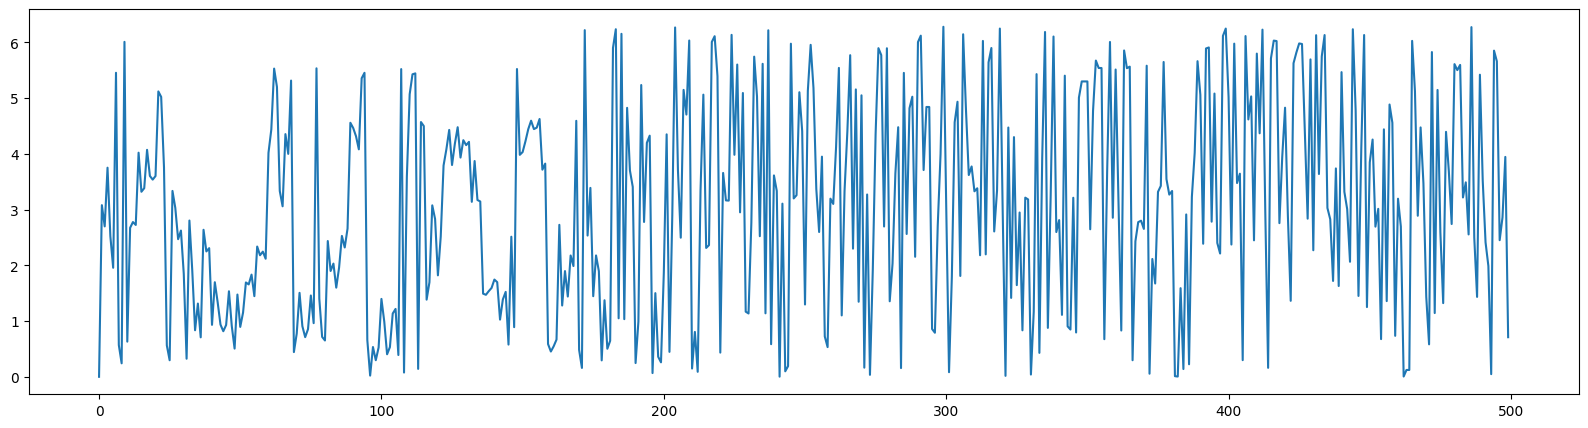

In [10]:
plt.figure(figsize=(20, 5))
plt.plot(datas[2][:500])